# NeuroScape 2.0 (1980–2025): growth and cluster analyses

Exploratory notebook on the provisional NeuroScape 2.0 assembly including the 1980–1998 extension. It is not
part of the paper and does not touch the v1 data. It reruns the **quantitative** analyses of the paper on v2:

1. Volume: articles per year, article types and journals
2. Growth of neuroscience as a whole, over different year windows
3. Cluster growth (as in `results_03_growth_trends.ipynb`) on 1980–2025, compared with v1
4. Profile of the 1980–1998 articles: which clusters they fall into, and how well they fit
5. Cluster statistics (size, first article, Krackhardt E/I) v1 vs v2

Not rerun: citation-based analyses (added articles have no counts until the January 2027 refresh) and the
LLM-generated texts (cluster descriptions, dimensions, trends, global trends), which are carried over from v1.

**Caveats for 1980–1998** (`Added In = v2.0-early`): journals come from a proxy for the Scimago rule (journals in the
rule in at least 3 of 1999–2003, plus their earlier titles). Journals that ceased or declined before 1999 are missing.
PubMed abstract coverage is incomplete for 1980–1984, so those years are undercounted unevenly across journals.

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_context('notebook')
pd.set_option('display.max_colwidth', 60)

BASEPATH = os.environ.get('BASEPATH_V2', '/media/mario/HDD/Data/NeuroScape_v2')
csv_path = os.path.join(BASEPATH, 'Public', 'Data', 'CSV')
v1_csv_path = os.path.join(BASEPATH, 'Internal', 'Base', 'V1', 'CSV')

columns = ['Pmid', 'Type', 'Year', 'Cluster ID', 'Journal', 'Added In', 'Assignment Share']
article_df = pd.read_csv(os.path.join(csv_path, 'neuroscience_articles_1980-2025.csv'), usecols=columns)
cluster_df = pd.read_csv(os.path.join(csv_path, 'neuroscience_clusters_1980-2025.csv'))
v1_cluster_df = pd.read_csv(os.path.join(v1_csv_path, 'neuroscience_clusters_1999-2023.csv'))
cluster_titles = cluster_df.set_index('Cluster ID')['Title'].str.split(':').str[0]

v1_df = article_df[article_df['Added In'] == 'v1.0']
early_df = article_df[article_df['Added In'] == 'v2.0-early']
PERIODS = [1979, 1984, 1989, 1994, 1998, 2023, 2025]
PERIOD_LABELS = ['1980-84', '1985-89', '1990-94', '1995-98', '1999-2023', '2024-25']

print(f'{len(article_df):,} articles in v2: ' + ', '.join(
    f'{key} {value:,}' for key, value in article_df['Added In'].value_counts().items()))

689,022 articles in v2: v1.0 461,316, v2.0-early 148,529, v2.0 60,993, v2.0-late 18,184


In [2]:
def compute_normalized_annual_growth(data):
    """
    Size-adjusted annual growth rate of each cluster (as in results_03): the slope of a linear fit to the
    cluster's annual article count, divided by its total number of articles.
    """
    cluster_count_per_year = data.groupby(['Year', 'Cluster ID']).size().unstack().fillna(0)
    beta = cluster_count_per_year.apply(
        lambda x: pd.Series(
            np.polyfit(cluster_count_per_year.index, x, 1), index=['Slope', 'Intercept']), axis=0)

    return beta.loc['Slope'] / cluster_count_per_year.sum()


def compute_field_growth(data):
    """
    Size-adjusted annual growth rate of neuroscience as a whole (as in results_03).
    """
    count_per_year = data.groupby('Year').size()
    slope = np.polyfit(count_per_year.index, count_per_year.values, 1)[0]

    return slope / count_per_year.sum()


def compute_exponential_growth(data):
    """
    Annual growth in percent from a log-linear fit to the annual article count.
    """
    count_per_year = data.groupby('Year').size()
    slope = np.polyfit(count_per_year.index, np.log(count_per_year.values), 1)[0]

    return 100 * (np.exp(slope) - 1)


def growth_class(growth, field_growth):
    return pd.cut(growth, [-np.inf, 0, field_growth, np.inf], labels=['Declining', 'Stable', 'Growing'],
                  right=False)


def window(data, start, end):
    return data[(data['Year'] >= start) & (data['Year'] <= end)]


def shade_early(ax, label=True):
    ax.axvspan(1979.5, 1998.5, color='grey', alpha=0.12, label='v2.0-early (proxy journals)' if label else None)
    ax.axvspan(1979.5, 1984.5, color='grey', alpha=0.12, label='incomplete abstracts' if label else None)


def plot_cluster_counts(data, clusters, title):
    counts = data[data['Cluster ID'].isin(clusters)].groupby(['Year', 'Cluster ID']).size().unstack().fillna(0)
    colors = sns.color_palette('colorblind', len(clusters))
    fig, ax = plt.subplots(figsize=(10, 5))
    shade_early(ax, label=False)
    for color, cluster in zip(colors, clusters):
        ax.plot(counts.index, counts[cluster], color=color, linewidth=1.5,
                label=f'{cluster:3d} {cluster_titles[cluster][:45]}')
    ax.set_xlabel('Year')
    ax.set_ylabel('Number of Articles')
    ax.set_title(title)
    ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left')
    sns.despine()
    plt.tight_layout()
    plt.show()

## 1. Volume

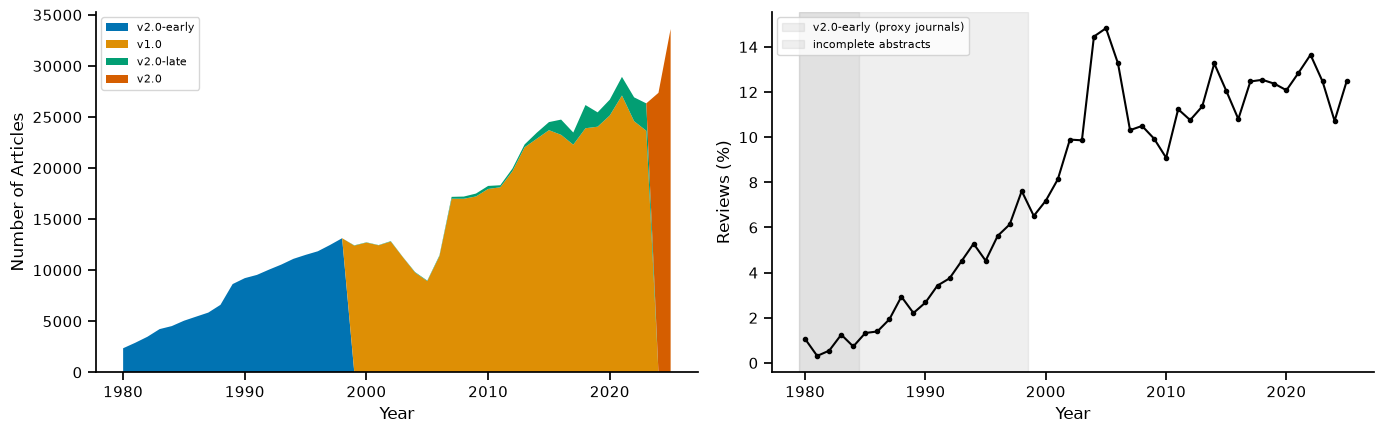

,Articles,Per_Year,Reviews_Pct,Journals
Year,,,,
1980-84,17493,3498.6,0.8,78
1985-89,31599,6319.8,2.0,101
1990-94,50485,10097.0,4.0,123
1995-98,48952,12238.0,6.0,136
1999-2023,479500,19180.0,11.5,382
2024-25,60993,30496.5,11.7,322


In [3]:
per_year = article_df.groupby(['Year', 'Added In']).size().unstack().fillna(0)
per_year = per_year[['v2.0-early', 'v1.0', 'v2.0-late', 'v2.0']]
type_per_year = article_df.groupby(['Year', 'Type']).size().unstack().fillna(0)
review_share = 100 * type_per_year['Review'] / type_per_year[['Research', 'Review']].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].stackplot(per_year.index, per_year.T.values, labels=per_year.columns,
                  colors=sns.color_palette('colorblind', 4))
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Articles')
axes[0].legend(loc='upper left', fontsize=8)

shade_early(axes[1])
axes[1].plot(review_share.index, review_share, marker='o', markersize=3, color='black')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Reviews (%)')
axes[1].legend(loc='upper left', fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()

article_df.groupby(pd.cut(article_df['Year'], PERIODS, labels=PERIOD_LABELS), observed=True).agg(
    Articles=('Pmid', 'size'), Per_Year=('Year', lambda y: len(y) / y.nunique()),
    Reviews_Pct=('Type', lambda t: 100 * (t == 'Review').mean()), Journals=('Journal', 'nunique')).round(1)

Top 10 journals in 1980–1998 and in 1999–2023 (all v2 articles of those years).

In [4]:
top_early = window(article_df, 1980, 1998)['Journal'].value_counts().head(10)
top_v1 = window(article_df, 1999, 2023)['Journal'].value_counts().head(10)
pd.DataFrame({'1980-1998': top_early.index, 'n (80-98)': top_early.values,
              '1999-2023': top_v1.index, 'n (99-23)': top_v1.values})

,1980-1998,n (80-98),1999-2023,n (99-23)
0,Brain research,12733,The Journal of neuroscience : the official journal of th...,23442
1,Neuroscience letters,12369,Neuroscience letters,15911
2,The Journal of neuroscience : the official journal of th...,7619,NeuroImage,15400
3,The Journal of comparative neurology,7227,Neuroscience,15202
4,Neuroscience,6534,Brain research,14537
5,Journal of neurochemistry,6466,Frontiers in neuroscience,11866
6,"Pharmacology, biochemistry, and behavior",5215,Proceedings of the National Academy of Sciences of the U...,10966
7,Journal of neurophysiology,4817,Journal of neurophysiology,10785
8,Experimental brain research,4597,Behavioural brain research,9449
9,Brain research bulletin,3743,Scientific reports,9103


## 2. Growth of neuroscience as a whole

The paper's measure (slope of a linear fit / total articles) depends on the window. Over 46 years growth is far
from linear, so the exponential rate (log-linear fit) is shown as well. `1985-2025` drops the years with
incomplete abstracts.

In [5]:
windows = {
    'v1 (1999-2023)': v1_df,
    'v2 1999-2025': window(article_df, 1999, 2025),
    'v2 1985-2025': window(article_df, 1985, 2025),
    'v2 1980-2025': article_df,
    'v2 1980-1998': window(article_df, 1980, 1998),
}
pd.DataFrame({
    'Articles': {name: len(data) for name, data in windows.items()},
    'Normalized growth': {name: round(compute_field_growth(data), 5) for name, data in windows.items()},
    'Exponential growth (%/yr)': {name: round(compute_exponential_growth(data), 2) for name, data in windows.items()},
})

,Articles,Normalized growth,Exponential growth (%/yr)
v1 (1999-2023),461316,0.00153,4.17
v2 1999-2025,540493,0.00151,4.44
v2 1985-2025,671529,0.00091,4.05
v2 1980-2025,689022,0.00086,4.79
v2 1980-1998,148529,0.00419,9.61


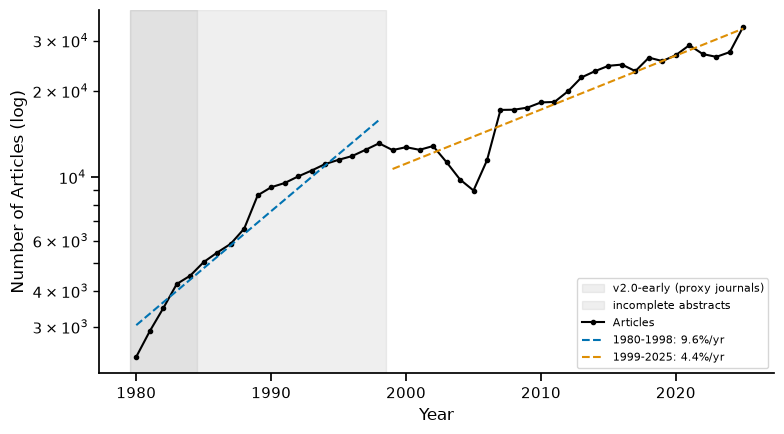

In [6]:
count_per_year = article_df.groupby('Year').size()
fig, ax = plt.subplots(figsize=(8, 4.5))
shade_early(ax)
ax.plot(count_per_year.index, count_per_year.values, marker='o', markersize=3, color='black', label='Articles')
for (start, end), color in zip([(1980, 1998), (1999, 2025)], sns.color_palette('colorblind', 2)):
    part = count_per_year.loc[start:end]
    slope, intercept = np.polyfit(part.index, np.log(part.values), 1)
    ax.plot(part.index, np.exp(intercept + slope * part.index), color=color, linestyle='--',
            label=f'{start}-{end}: {100 * (np.exp(slope) - 1):.1f}%/yr')
ax.set_yscale('log')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Articles (log)')
ax.legend(fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()

## 3. Cluster growth (as in Figure 3 of the paper)

Growth classes: **Growing** (above the field's normalized growth), **Stable** (0 to field growth), **Declining** (< 0),
computed per window with the field growth of that window.

In [7]:
growth = {name: compute_normalized_annual_growth(data) for name, data in windows.items() if name != 'v2 1980-1998'}
classes = {name: growth_class(growth[name], compute_field_growth(windows[name])) for name in growth}

class_counts = pd.DataFrame({name: c.value_counts() for name, c in classes.items()}).loc[['Growing', 'Stable', 'Declining']]
display(class_counts)

print('v1 (1999-2023) vs v2 1980-2025:')
display(pd.crosstab(classes['v1 (1999-2023)'].rename('v1'), classes['v2 1980-2025'].rename('v2 1980-2025'), margins=True))
print('v1 (1999-2023) vs v2 1985-2025:')
display(pd.crosstab(classes['v1 (1999-2023)'].rename('v1'), classes['v2 1985-2025'].rename('v2 1985-2025'), margins=True))

,v1 (1999-2023),v2 1999-2025,v2 1985-2025,v2 1980-2025
Growing,91,90,108,108
Stable,57,57,48,52
Declining,27,28,19,15


v1 (1999-2023) vs v2 1980-2025:


v2 1980-2025,Declining,Stable,Growing,All
v1,,,,
Declining,13,14,0,27
Stable,2,36,19,57
Growing,0,2,89,91
All,15,52,108,175


v1 (1999-2023) vs v2 1985-2025:


v2 1985-2025,Declining,Stable,Growing,All
v1,,,,
Declining,17,10,0,27
Stable,2,36,19,57
Growing,0,2,89,91
All,19,48,108,175


The 10 fastest growing and declining clusters over 1980–2025, with their rank in v1 (growing: descending, declining: ascending).

In [8]:
num_selected = 10
v1_growth, v2_growth = growth['v1 (1999-2023)'], growth['v2 1980-2025']
v1_field, v2_field = compute_field_growth(v1_df), compute_field_growth(article_df)

v1_growing = set(v1_growth[v1_growth > v1_field].sort_values(ascending=False).head(num_selected).index)
v1_declining = set(v1_growth[v1_growth < 0].sort_values().head(num_selected).index)
v2_growing = v2_growth[v2_growth > v2_field].sort_values(ascending=False).head(num_selected).index
v2_declining = v2_growth[v2_growth < 0].sort_values().head(num_selected).index


def selection_table(clusters, v1_selection, ascending):
    return pd.DataFrame({
        'Title': cluster_titles[clusters],
        'Growth 1980-2025': v2_growth[clusters].round(4),
        'Growth v1': v1_growth[clusters].round(4),
        'v1 Rank': v1_growth.rank(ascending=ascending).astype(int)[clusters],
        'In v1 Top 10': [cluster in v1_selection for cluster in clusters],
        'Share 1980-98 (%)': (100 * early_df['Cluster ID'].value_counts().reindex(clusters).fillna(0)
                              / article_df['Cluster ID'].value_counts()[clusters]).round(1),
    })


display(selection_table(v2_growing, v1_growing, ascending=False))
display(selection_table(v2_declining, v1_declining, ascending=True))

,Title,Growth 1980-2025,Growth v1,v1 Rank,In v1 Top 10,Share 1980-98 (%)
Cluster ID,,,,,,
171,Neurological and Neuropsychiatric Manifestations of COVI...,0.0024,0.0080,1,True,0.0
173,Neurodegenerative Disease Communication Through Exosomes,0.0023,0.0067,2,True,0.3
167,Exploring Non-Invasive Vagus Nerve Stimulation,0.0022,0.0062,3,True,0.9
94,Advancements in EEG-based Brain-Computer Interfaces for ...,0.0021,0.0053,4,True,1.0
69,MicroRNA Regulation in Alzheimer's Disease,0.0020,0.0052,5,True,0.2
96,Neurocognitive Connectivity and Dysfunction in PTSD Acro...,0.0019,0.0046,7,True,2.2
141,Transcriptomic Insights into Cell-Type Diversity and Neu...,0.0019,0.0044,10,True,2.9
104,Effects of Physical Exercise on Neurogenesis and Cogniti...,0.0019,0.0041,18,False,1.3
120,Innovations in Neuromorphic Computing,0.0019,0.0049,6,True,3.3


,Title,Growth 1980-2025,Growth v1,v1 Rank,In v1 Top 10,Share 1980-98 (%)
Cluster ID,,,,,,
124,Neuropeptide Regulation of Hypothalamic Gonadotropin-Rel...,-0.0007,-0.0023,3,True,63.4
75,Dopamine Receptor Interactions and Their Impact on Stria...,-0.0005,-0.0019,7,True,59.7
135,Purinergic Signaling in Neuronal and Glial Function,-0.0005,-0.0027,2,True,55.3
49,Diversity and Specialization in Corticothalamic and Pyra...,-0.0004,-0.0002,22,False,57.3
9,Calcium Channels in Synaptic Transmission and Neuronal M...,-0.0003,-0.0021,5,True,51.3
41,Mechanisms of Opioid Dependence and Tolerance,-0.0002,-0.0006,13,False,48.6
55,Explorations in GABAergic Synaptic and Extrasynaptic Dyn...,-0.0002,-0.0016,9,True,46.3
42,Investigation of Serotonin Receptors and Adaptations in ...,-0.0002,-0.0009,12,False,47.6
102,The Multifaceted Roles of Nitric Oxide in Neuronal Funct...,-0.0001,-0.0034,1,True,46.5


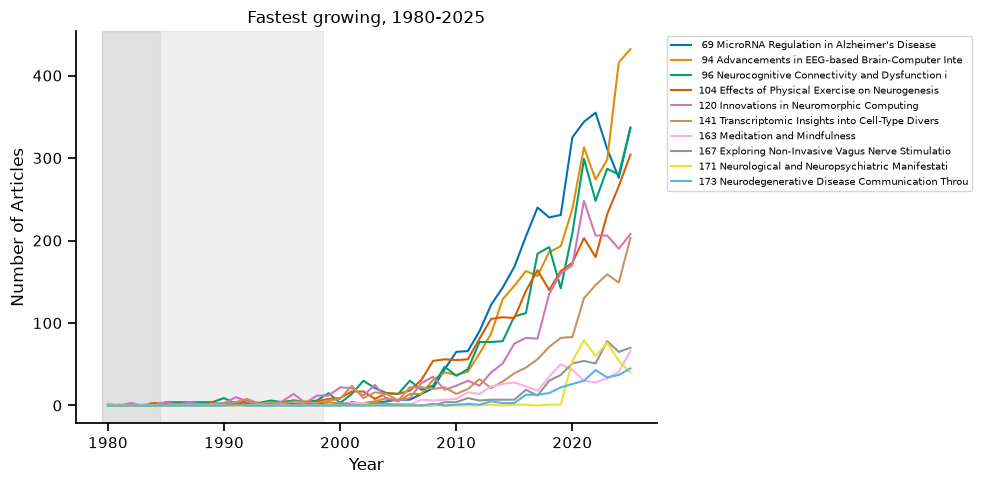

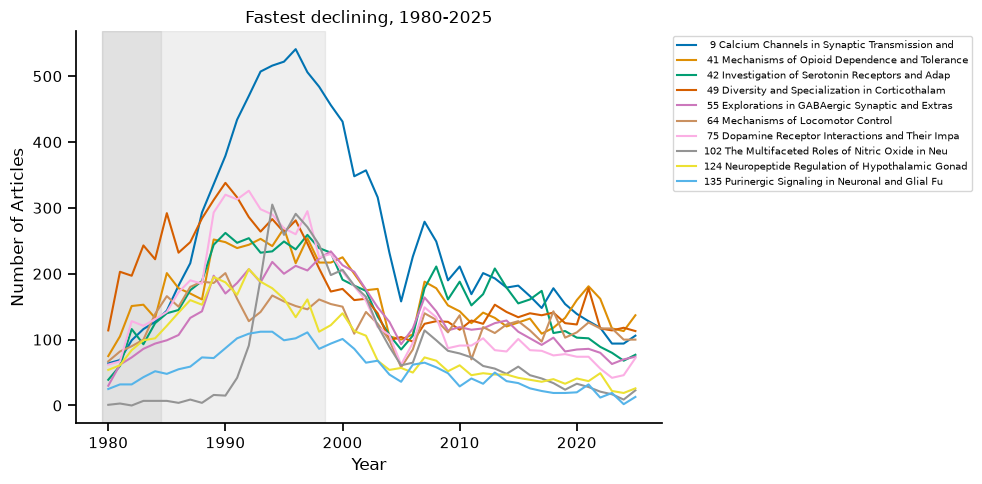

In [9]:
plot_cluster_counts(article_df, sorted(v2_growing), 'Fastest growing, 1980-2025')
plot_cluster_counts(article_df, sorted(v2_declining), 'Fastest declining, 1980-2025')

Clusters whose classification changes between v1 and 1980–2025. Adding the early years mostly affects clusters that
were already large in the 1980s–1990s: a cluster that rose from 1980 to 2000 and then declined can look stable or
growing over 1980–2025 although it declined over 1999–2023.

In [10]:
changed = classes['v1 (1999-2023)'].astype(str) != classes['v2 1980-2025'].astype(str)
pd.DataFrame({
    'Title': cluster_titles[changed[changed].index],
    'v1': classes['v1 (1999-2023)'][changed],
    '1980-2025': classes['v2 1980-2025'][changed],
    '1985-2025': classes['v2 1985-2025'][changed],
    'Share 1980-98 (%)': (100 * early_df['Cluster ID'].value_counts().reindex(changed[changed].index).fillna(0)
                          / article_df['Cluster ID'].value_counts()[changed[changed].index]).round(1),
}).sort_values(['v1', '1980-2025'])

,Title,v1,1980-2025,1985-2025,Share 1980-98 (%)
Cluster ID,,,,,
14,The Role of Estrogen and Androgen Derivatives in Brain F...,Declining,Stable,Stable,31.9
22,Molecular Mechanisms of Synaptic Plasticity in the Hippo...,Declining,Stable,Stable,28.3
34,Neurogenesis and Cortical Development,Declining,Stable,Stable,29.1
35,Mechanisms and Dynamics of Axon Guidance and Neuronal Po...,Declining,Stable,Declining,34.6
43,Visual Processing,Declining,Stable,Stable,35.7
48,Apoptotic Pathways and Neurodegenerative Mechanisms in N...,Declining,Stable,Stable,25.9
57,Mechanisms of Synaptic Vesicle Exocytosis and Endocytosis,Declining,Stable,Stable,27.7
60,Mechanisms and Dynamics of AMPA Receptor Trafficking and...,Declining,Stable,Declining,39.4
79,Neural and Psychophysical Insights into Motion Perceptio...,Declining,Stable,Stable,29.7


**Peak year.** Linear growth cannot express rise and fall. The year in which a cluster's share of all articles
(3-year rolling mean) peaks gives a complementary view, now that the series starts in 1980.

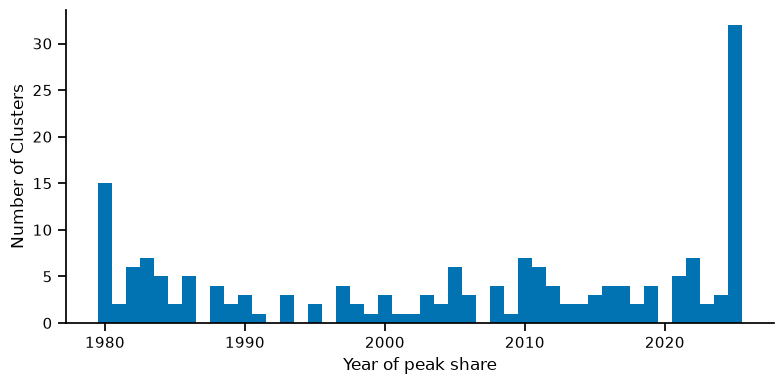

63 clusters peak (in share) before 1999.


,Title,Peak Year,v1 Class
Cluster ID,,,
168,Neurocognitive Mechanisms and Indicators,1980,Growing
50,Mechanisms of Myelination and Remyelination in CNS,1980,Stable
68,Circadian Rhythm Mechanisms and Influencing Factors,1980,Stable
78,Vestibular System Functionality and Its Influence on Spa...,1980,Stable
98,Hypothermia and Neuroprotection in Neonatal Hypoxia-Isch...,1980,Stable
...,...,...,...
29,Spatial Memory and Navigation,1997,Growing
22,Molecular Mechanisms of Synaptic Plasticity in the Hippo...,1997,Declining
89,Neurotrophin Signaling in Neuronal Development and Function,1997,Declining


In [11]:
share = (article_df.groupby(['Year', 'Cluster ID']).size().unstack().fillna(0)
         .div(article_df.groupby('Year').size(), axis=0))
peak_year = share.rolling(3, center=True, min_periods=1).mean().idxmax()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(peak_year, bins=np.arange(1979.5, 2026.5, 1), color=sns.color_palette('colorblind')[0])
ax.set_xlabel('Year of peak share')
ax.set_ylabel('Number of Clusters')
sns.despine()
plt.tight_layout()
plt.show()

peaked_early = peak_year[peak_year <= 1998].index
print(f'{len(peaked_early)} clusters peak (in share) before 1999.')
pd.DataFrame({'Title': cluster_titles[peaked_early], 'Peak Year': peak_year[peaked_early],
              'v1 Class': classes['v1 (1999-2023)'][peaked_early]}).sort_values('Peak Year')

## 4. The 1980–1998 articles: where they fall and how well they fit

,n,median,below_half
Year,,,
1980-84,17493,0.701,0.274
1985-89,31599,0.723,0.252
1990-94,50485,0.764,0.224
1995-98,48952,0.821,0.181
1999-2023,18184,0.845,0.156
2024-25,60993,0.841,0.162


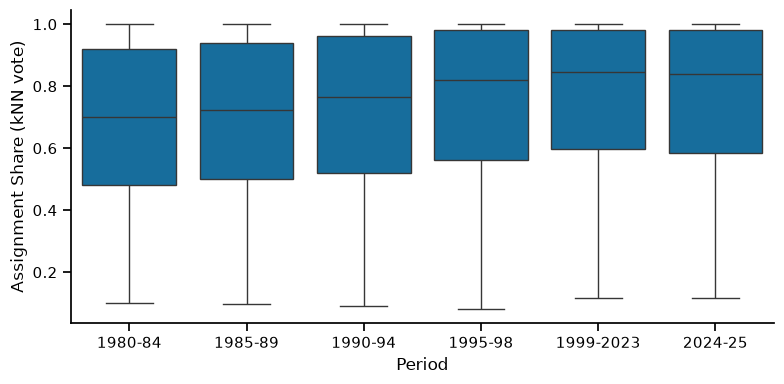

In [12]:
period = pd.cut(article_df['Year'], PERIODS, labels=PERIOD_LABELS)
assigned = article_df[article_df['Assignment Share'].notna()]
display(assigned.groupby(period[assigned.index], observed=True)['Assignment Share'].agg(
    n='size', median='median', below_half=lambda s: (s < 0.5).mean()).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=period[assigned.index], y=assigned['Assignment Share'], color=sns.color_palette('colorblind')[0],
            fliersize=0, ax=ax)
ax.set_xlabel('Period')
ax.set_ylabel('Assignment Share (kNN vote)')
sns.despine()
plt.tight_layout()
plt.show()

Clusters with the largest share of their articles from 1980–1998, and with the weakest fit of their early articles (at least 200 early articles).

In [13]:
early_by_cluster = early_df.groupby('Cluster ID').agg(Early=('Pmid', 'size'), Median_Share=('Assignment Share', 'median'))
early_by_cluster['Size'] = article_df['Cluster ID'].value_counts()
early_by_cluster['Early (%)'] = (100 * early_by_cluster['Early'] / early_by_cluster['Size']).round(1)
early_by_cluster['Title'] = cluster_titles
early_by_cluster = early_by_cluster[['Title', 'Size', 'Early', 'Early (%)', 'Median_Share']]

display(early_by_cluster.sort_values('Early (%)', ascending=False).head(10))
display(early_by_cluster[early_by_cluster['Early'] >= 200].sort_values('Median_Share').head(10).round(3))

,Title,Size,Early,Early (%),Median_Share
Cluster ID,,,,,
124,Neuropeptide Regulation of Hypothalamic Gonadotropin-Rel...,4204,2667,63.4,0.542759
75,Dopamine Receptor Interactions and Their Impact on Stria...,6849,4087,59.7,0.700638
49,Diversity and Specialization in Corticothalamic and Pyra...,8426,4832,57.3,0.683361
135,Purinergic Signaling in Neuronal and Glial Function,2550,1411,55.3,0.447318
9,Calcium Channels in Synaptic Transmission and Neuronal M...,11707,6005,51.3,0.728489
72,Neuroendocrine and Autonomic Mechanisms in Cardiovascula...,6248,3116,49.9,0.824758
116,Neurophysiological Mechanisms Underlying Swallowing and ...,3782,1869,49.4,0.704715
41,Mechanisms of Opioid Dependence and Tolerance,7736,3761,48.6,0.980270
42,Investigation of Serotonin Receptors and Adaptations in ...,7429,3539,47.6,0.799912


,Title,Size,Early,Early (%),Median_Share
Cluster ID,,,,,
164,Role of Perineuronal Nets in Regulating Synaptic Plastic...,626,213,34.0,0.421
130,Astrocytes,1812,372,20.5,0.423
128,Advanced Behavioral Analysis and Tracking in Laboratory ...,1825,224,12.3,0.443
135,Purinergic Signaling in Neuronal and Glial Function,2550,1411,55.3,0.447
142,Glioblastoma,1461,253,17.3,0.477
93,Mitochondrial Dynamics and Mitophagy in Neurodegeneration,2900,216,7.4,0.481
131,Neuronal Hyperexcitability and Genetic Overlaps in Migra...,2034,304,14.9,0.496
134,Innovative Strategies for Blood-Brain Barrier Translocat...,1681,353,21.0,0.507
121,Mechanisms of mRNA Localization and Local Translation in...,2152,290,13.5,0.507


## 5. Cluster statistics, v1 vs v2

Clusters whose first article is now before 1999: 174 of 175
Median size v1 -> v2: 2472.0 -> 3621.0


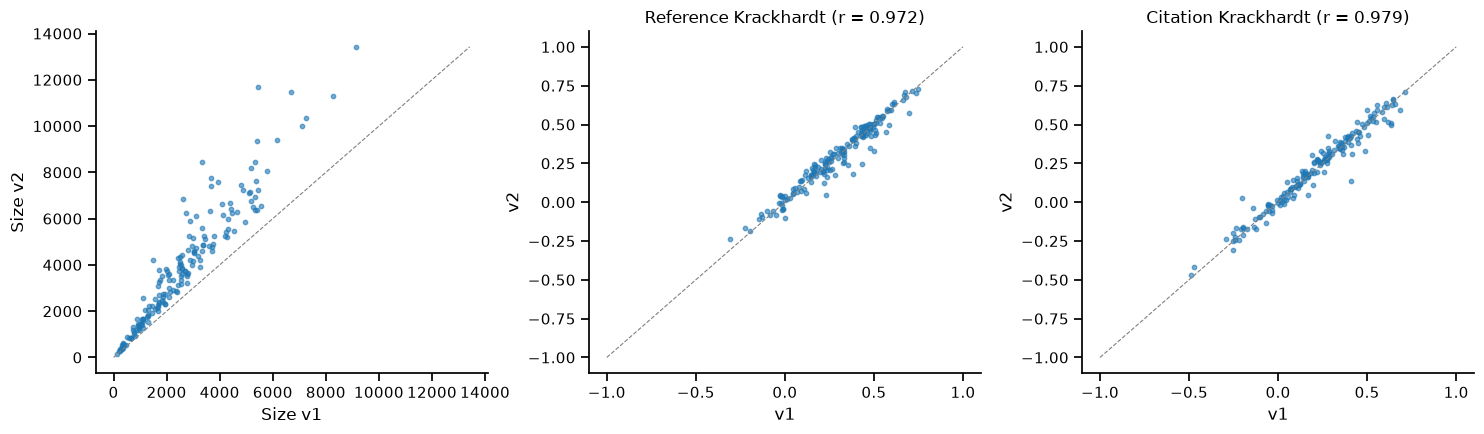

Reference Krackhardt: sign changed for 6 clusters; median abs change 0.027
Citation Krackhardt: sign changed for 4 clusters; median abs change 0.023


In [14]:
compare = v1_cluster_df.set_index('Cluster ID')[['Size', 'Year First Article', 'Reference Krackhardt', 'Citation Krackhardt']].join(
    cluster_df.set_index('Cluster ID')[['Size', 'Year First Article', 'Reference Krackhardt', 'Citation Krackhardt']],
    lsuffix=' v1', rsuffix=' v2')

print('Clusters whose first article is now before 1999:', (compare['Year First Article v2'] < 1999).sum(), 'of', len(compare))
print('Median size v1 -> v2:', compare['Size v1'].median(), '->', compare['Size v2'].median())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(compare['Size v1'], compare['Size v2'], s=10, alpha=0.6)
axes[0].plot([0, compare['Size v2'].max()], [0, compare['Size v2'].max()], color='grey', linestyle='--', linewidth=0.8)
axes[0].set_xlabel('Size v1')
axes[0].set_ylabel('Size v2')
for ax, column in zip(axes[1:], ['Reference Krackhardt', 'Citation Krackhardt']):
    ax.scatter(compare[f'{column} v1'], compare[f'{column} v2'], s=10, alpha=0.6)
    ax.plot([-1, 1], [-1, 1], color='grey', linestyle='--', linewidth=0.8)
    r = compare[[f'{column} v1', f'{column} v2']].corr().iloc[0, 1]
    ax.set_title(f'{column} (r = {r:.3f})')
    ax.set_xlabel('v1')
    ax.set_ylabel('v2')
sns.despine()
plt.tight_layout()
plt.show()

for column in ['Reference Krackhardt', 'Citation Krackhardt']:
    sign_v1, sign_v2 = np.sign(compare[f'{column} v1']), np.sign(compare[f'{column} v2'])
    print(f'{column}: sign changed for {(sign_v1 != sign_v2).sum()} clusters; '
          f'median abs change {(compare[f"{column} v2"] - compare[f"{column} v1"]).abs().median():.3f}')